# 🏠 California House Price Prediction — Linear Regression from Scratch → Gradient Boosting

Predict the median house value of a California district from census data (location, rooms, population, income, distance to the ocean).

What makes this project different:
1. **Linear Regression implemented from scratch** with NumPy and gradient descent, plugged into a scikit-learn `Pipeline`, and verified against scikit-learn.
2. **Feature engineering + tree ensembles** to push the score well beyond the linear baseline.

**Author:** Reda Akram · Computer Science (AI), University of Technology – Baghdad

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
sns.set_theme(style="whitegrid"); RANDOM_STATE = 42

## 1. Data

In [2]:
df = pd.read_csv("data/housing.csv")
print(df.shape)
print(df.isnull().sum()[lambda s: s > 0])
df.head()

(20640, 10)
total_bedrooms    207
dtype: int64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. EDA

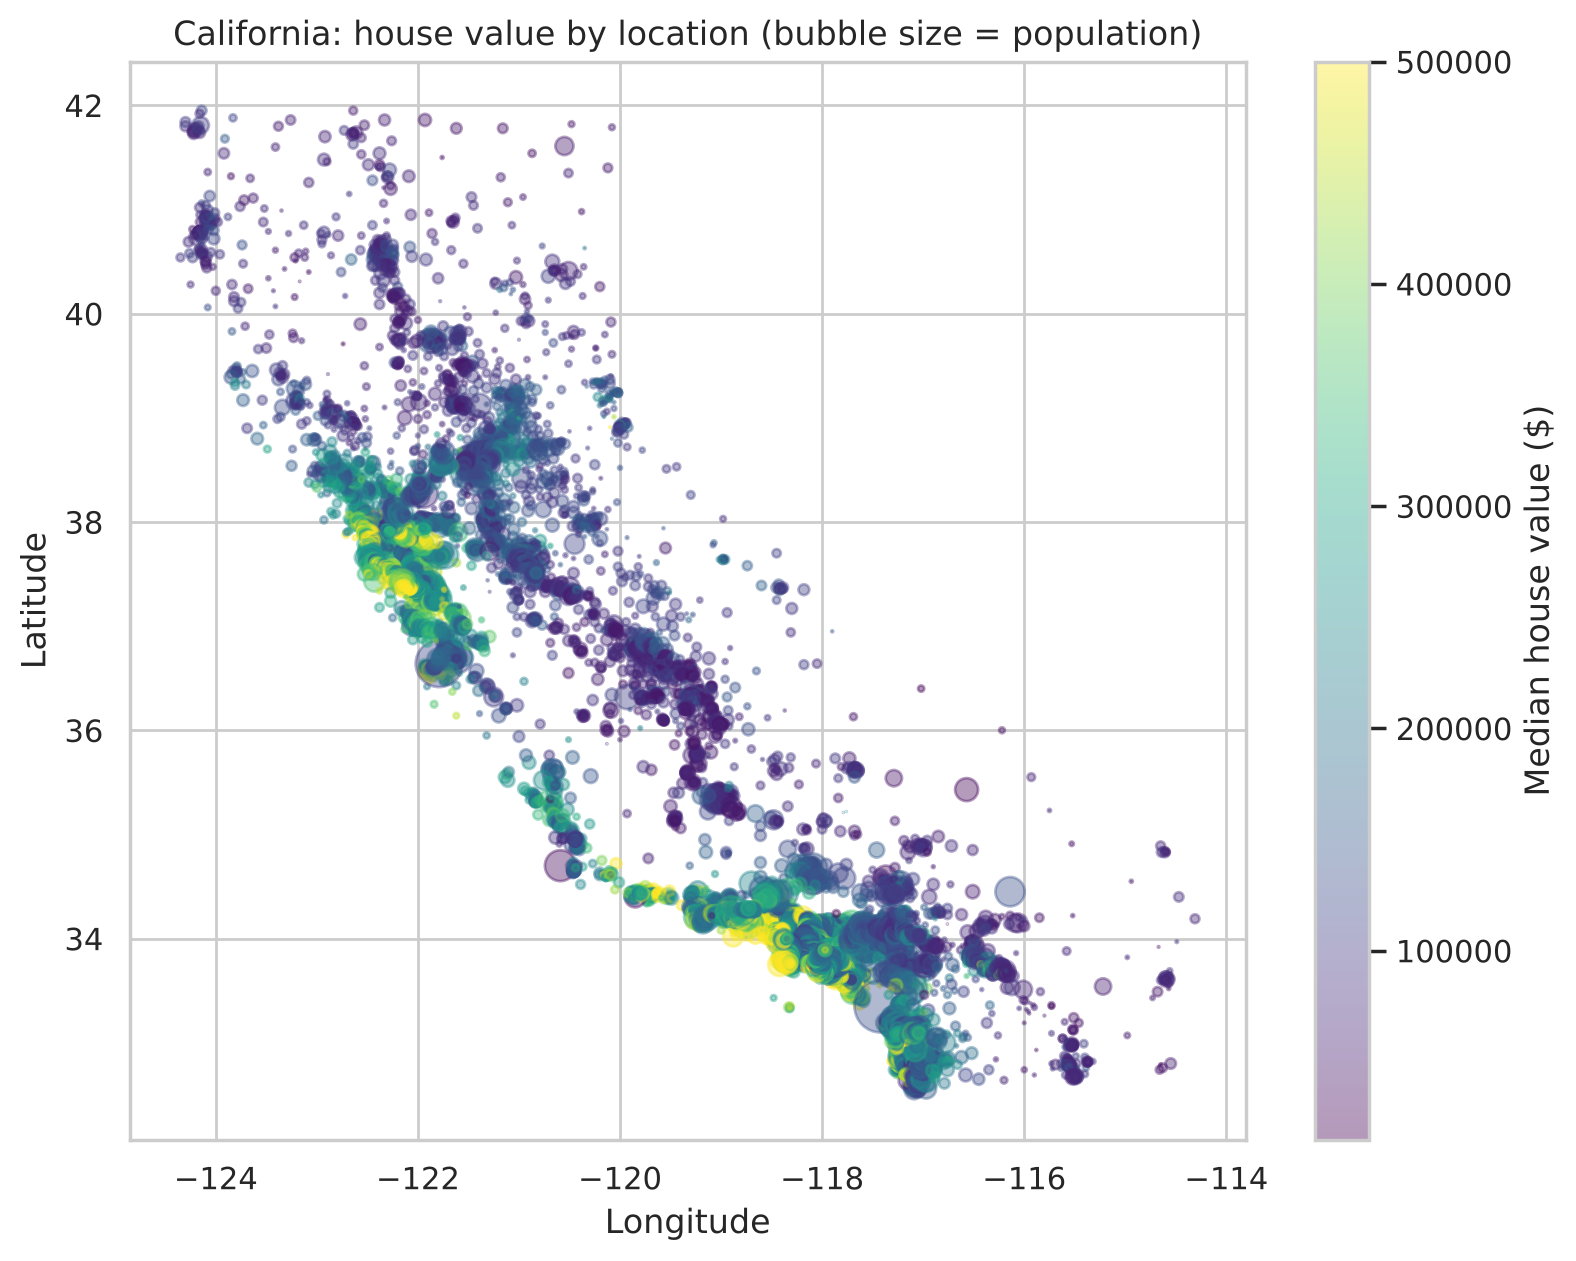

In [3]:
fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(df.longitude, df.latitude, c=df.median_house_value, s=df.population / 100, cmap="viridis", alpha=0.4)
plt.colorbar(sc, label="Median house value ($)"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("California: house value by location (bubble size = population)")
plt.savefig("images/california_map.png", dpi=120, bbox_inches="tight"); plt.show()

Prices are highest along the coast (Bay Area and Los Angeles) — **location matters a lot**, and its effect is not linear.

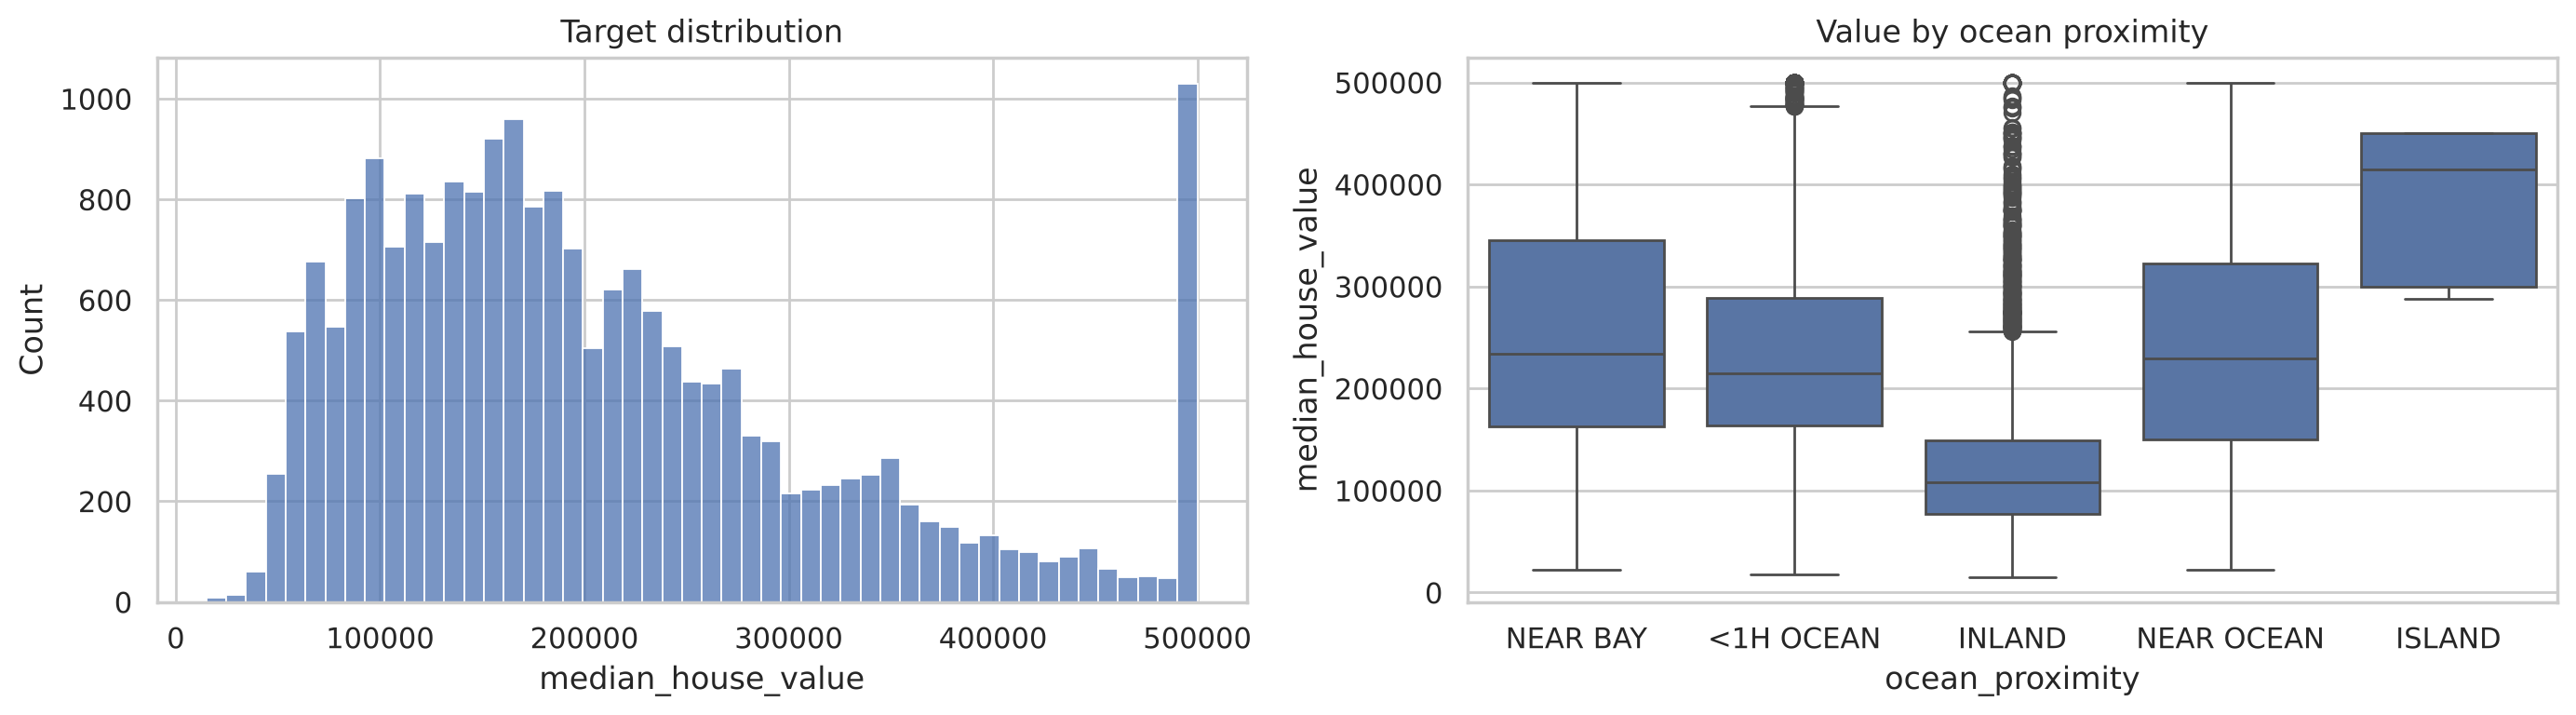

Districts capped at $500,001: 965


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df.median_house_value, bins=50, ax=axes[0]); axes[0].set_title("Target distribution")
sns.boxplot(data=df, x="ocean_proximity", y="median_house_value", ax=axes[1]); axes[1].set_title("Value by ocean proximity")
plt.tight_layout(); plt.savefig("images/target_and_ocean.png", dpi=120, bbox_inches="tight"); plt.show()
print("Districts capped at $500,001:", (df.median_house_value >= 500001).sum())

* The target is **capped at $500,001** (the spike on the right): the census didn't record values above that, so the model can never predict higher.
* `INLAND` districts are much cheaper; `ISLAND` is rare but expensive.

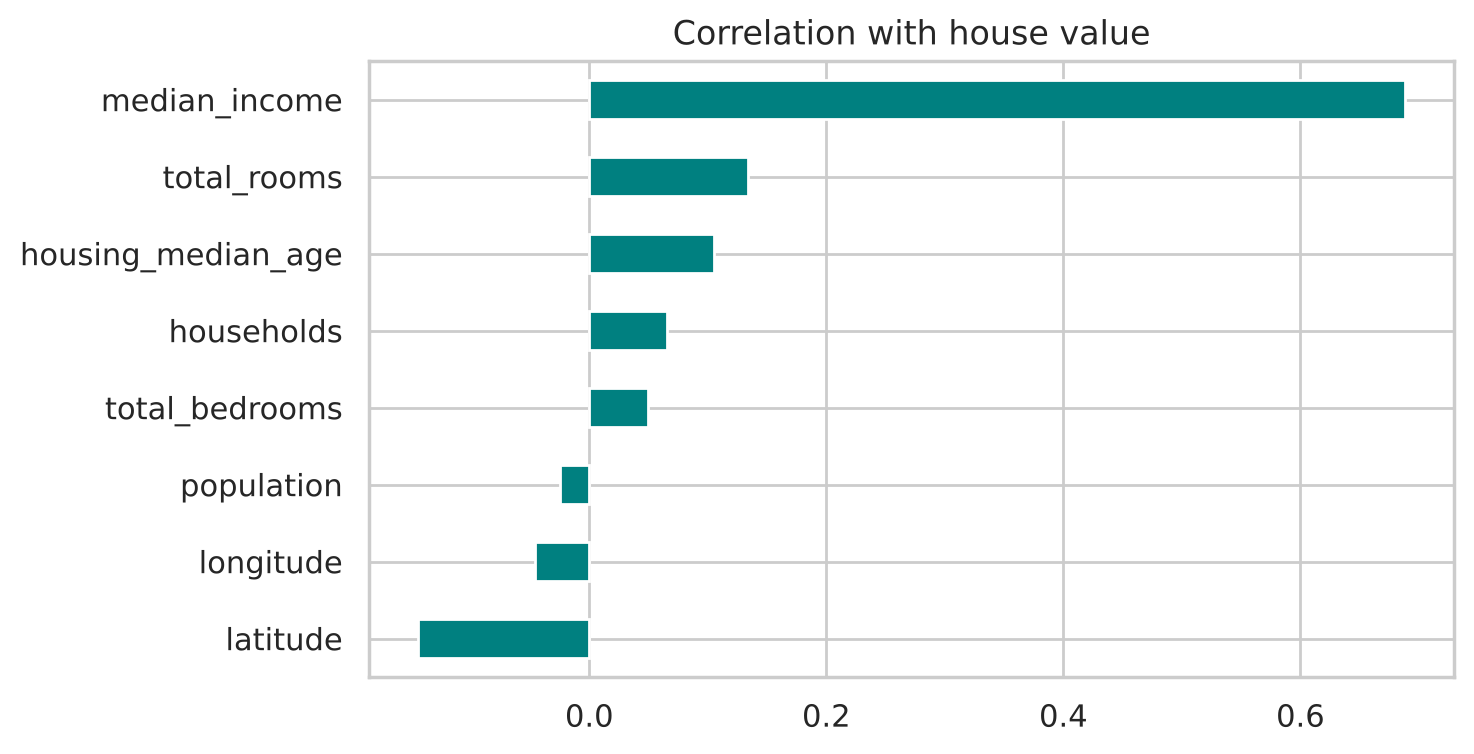

In [5]:
df.corr(numeric_only=True)["median_house_value"].drop("median_house_value").sort_values().plot(kind="barh", figsize=(7, 4), color="teal")
plt.title("Correlation with house value"); plt.savefig("images/correlation.png", dpi=120, bbox_inches="tight"); plt.show()

**Median income** is the single strongest predictor.

## 3. Linear Regression from scratch (gradient descent)

Model: $\hat{y} = Xw + b$  Cost: $J = \frac{1}{2m}\sum(\hat{y}-y)^2$

Gradients: $\frac{\partial J}{\partial w} = \frac{1}{m}X^T(\hat{y}-y)$, $\frac{\partial J}{\partial b} = \frac{1}{m}\sum(\hat{y}-y)$

The class inherits from scikit-learn's `BaseEstimator` so it can live inside a `Pipeline`, and it records the cost at each iteration so we can see it converge.

In [6]:
class LinearRegressionFromScratch(BaseEstimator, RegressorMixin):
    def __init__(self, lr=0.09, iterations=1000):
        self.lr = lr
        self.iterations = iterations

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        m, n = X.shape
        self.w_, self.b_, self.cost_history_ = np.zeros(n), 0.0, []
        for _ in range(self.iterations):
            error = X @ self.w_ + self.b_ - y
            self.cost_history_.append((1 / (2 * m)) * np.sum(error ** 2))
            self.w_ -= self.lr * (1 / m) * (X.T @ error)
            self.b_ -= self.lr * (1 / m) * np.sum(error)
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

In [7]:
X = df.drop(columns="median_house_value"); y = df["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

num_features = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income"]
cat_features = ["ocean_proximity"]

def make_preprocessor(num):
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
    ])

def evaluate(name, model):
    model.fit(X_train, y_train); pred = model.predict(X_test)
    return {"model": name, "R²": r2_score(y_test, pred), "RMSE ($)": root_mean_squared_error(y_test, pred), "MAE ($)": mean_absolute_error(y_test, pred)}

scratch = Pipeline([("prep", make_preprocessor(num_features)), ("model", LinearRegressionFromScratch(lr=0.09, iterations=1000))])
sk_lr   = Pipeline([("prep", make_preprocessor(num_features)), ("model", LinearRegression())])
results = [evaluate("Linear Regression (from scratch, GD)", scratch), evaluate("Linear Regression (scikit-learn)", sk_lr)]
pd.DataFrame(results).round(3)

,model,R²,RMSE ($),MAE ($)
0,"Linear Regression (from scratch, GD)",0.626,70032.987,50621.998
1,Linear Regression (scikit-learn),0.625,70059.193,50670.489


The from-scratch version reaches almost exactly the same score as scikit-learn's closed-form solution, which confirms the gradient-descent implementation is correct.

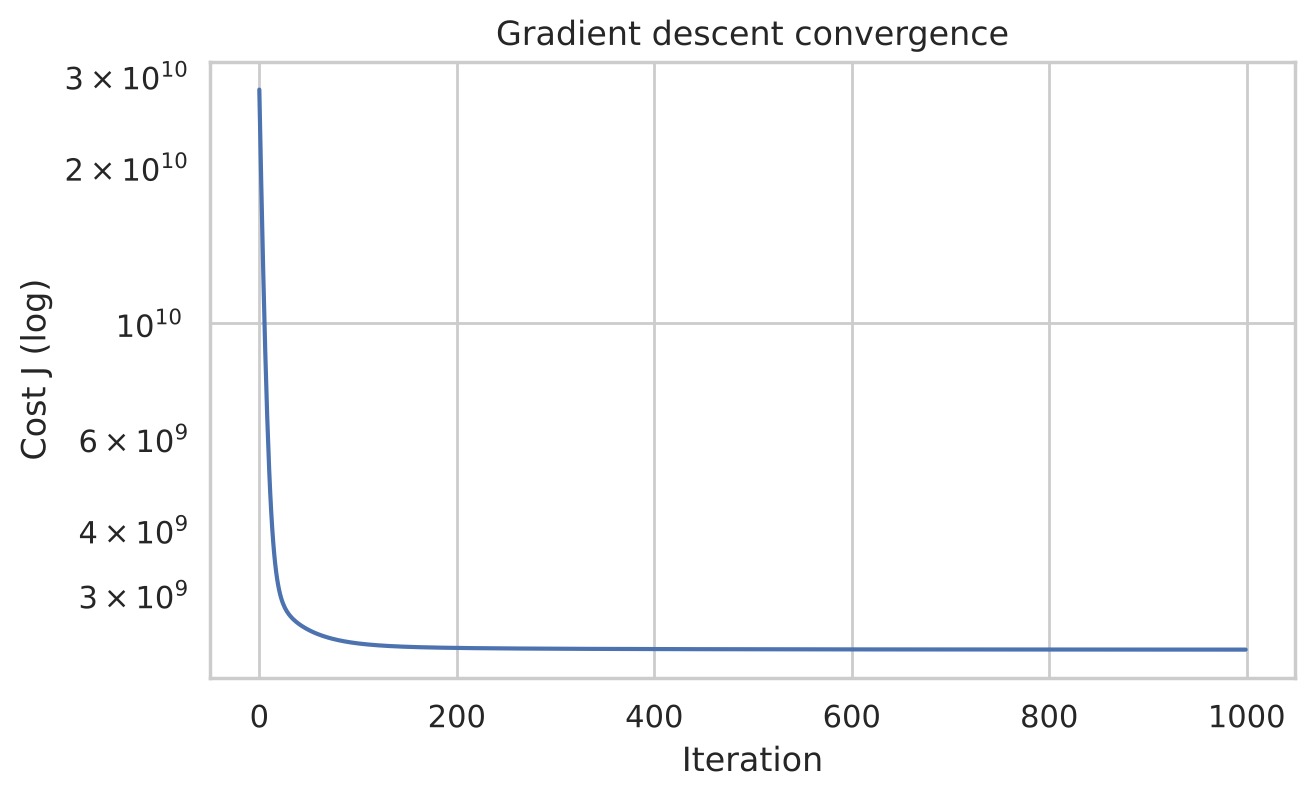

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(scratch.named_steps["model"].cost_history_)
plt.yscale("log"); plt.xlabel("Iteration"); plt.ylabel("Cost J (log)"); plt.title("Gradient descent convergence")
plt.savefig("images/gd_convergence.png", dpi=120, bbox_inches="tight"); plt.show()

## 4. Improving the model

A linear model scores R² ≈ 0.63, because (a) raw counts like `total_rooms` depend on district size, and (b) the effect of location is highly non-linear.

**Feature engineering** — ratios that describe a typical home rather than the whole district:
* `rooms_per_household`, `bedrooms_ratio`, `people_per_household`

In [9]:
def add_features(d):
    d = d.copy()
    d["rooms_per_household"] = d.total_rooms / d.households
    d["bedrooms_ratio"] = d.total_bedrooms / d.total_rooms
    d["people_per_household"] = d.population / d.households
    return d

X_train, X_test = add_features(X_train), add_features(X_test)
num_fe = num_features + ["rooms_per_household", "bedrooms_ratio", "people_per_household"]

results += [
    evaluate("Linear Regression + engineered features", Pipeline([("prep", make_preprocessor(num_fe)), ("model", LinearRegression())])),
    evaluate("Random Forest", Pipeline([("prep", make_preprocessor(num_fe)), ("model", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))])),
]
best = Pipeline([("prep", make_preprocessor(num_fe)), ("model", HistGradientBoostingRegressor(max_iter=600, learning_rate=0.08, max_leaf_nodes=48, random_state=RANDOM_STATE))])
results.append(evaluate("Histogram Gradient Boosting", best))
table = pd.DataFrame(results).round(3); table

,model,R²,RMSE ($),MAE ($)
0,"Linear Regression (from scratch, GD)",0.626,70032.987,50621.998
1,Linear Regression (scikit-learn),0.625,70059.193,50670.489
2,Linear Regression + engineered features,0.635,69127.038,49645.492
3,Random Forest,0.813,49499.516,31766.873
4,Histogram Gradient Boosting,0.849,44486.122,29174.227


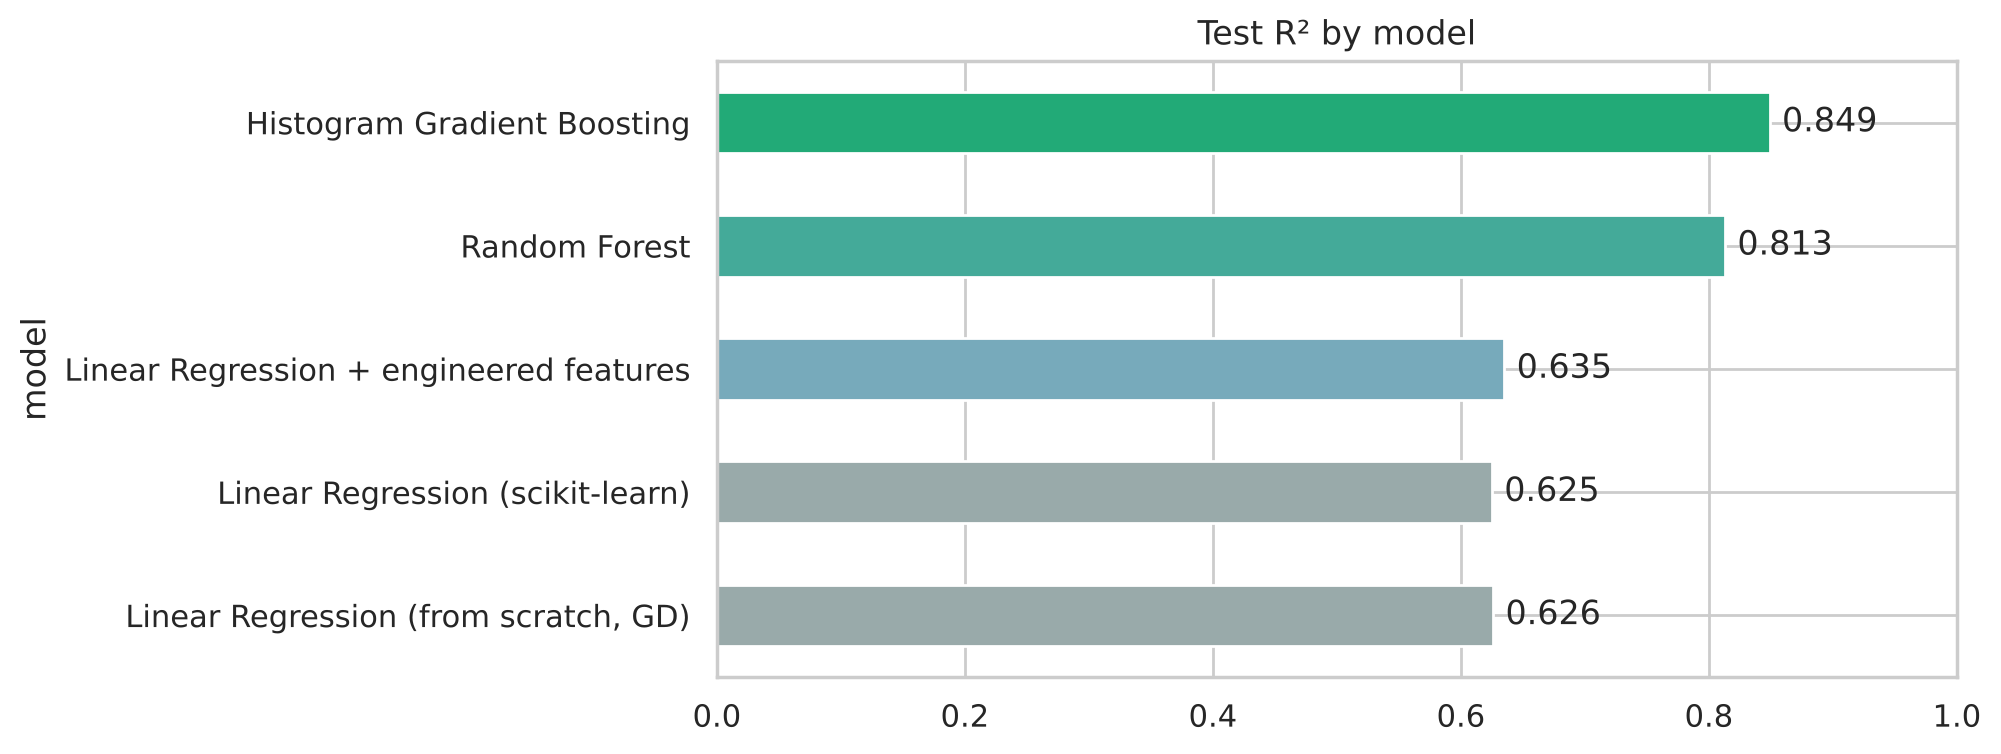

In [10]:
t = table.set_index("model")["R²"]
t.plot(kind="barh", figsize=(8, 4), color=["#9aa", "#9aa", "#7ab", "#4a9", "#2a7"]); plt.xlim(0, 1)
for i, v in enumerate(t): plt.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.title("Test R² by model"); plt.savefig("images/model_comparison.png", dpi=120, bbox_inches="tight"); plt.show()

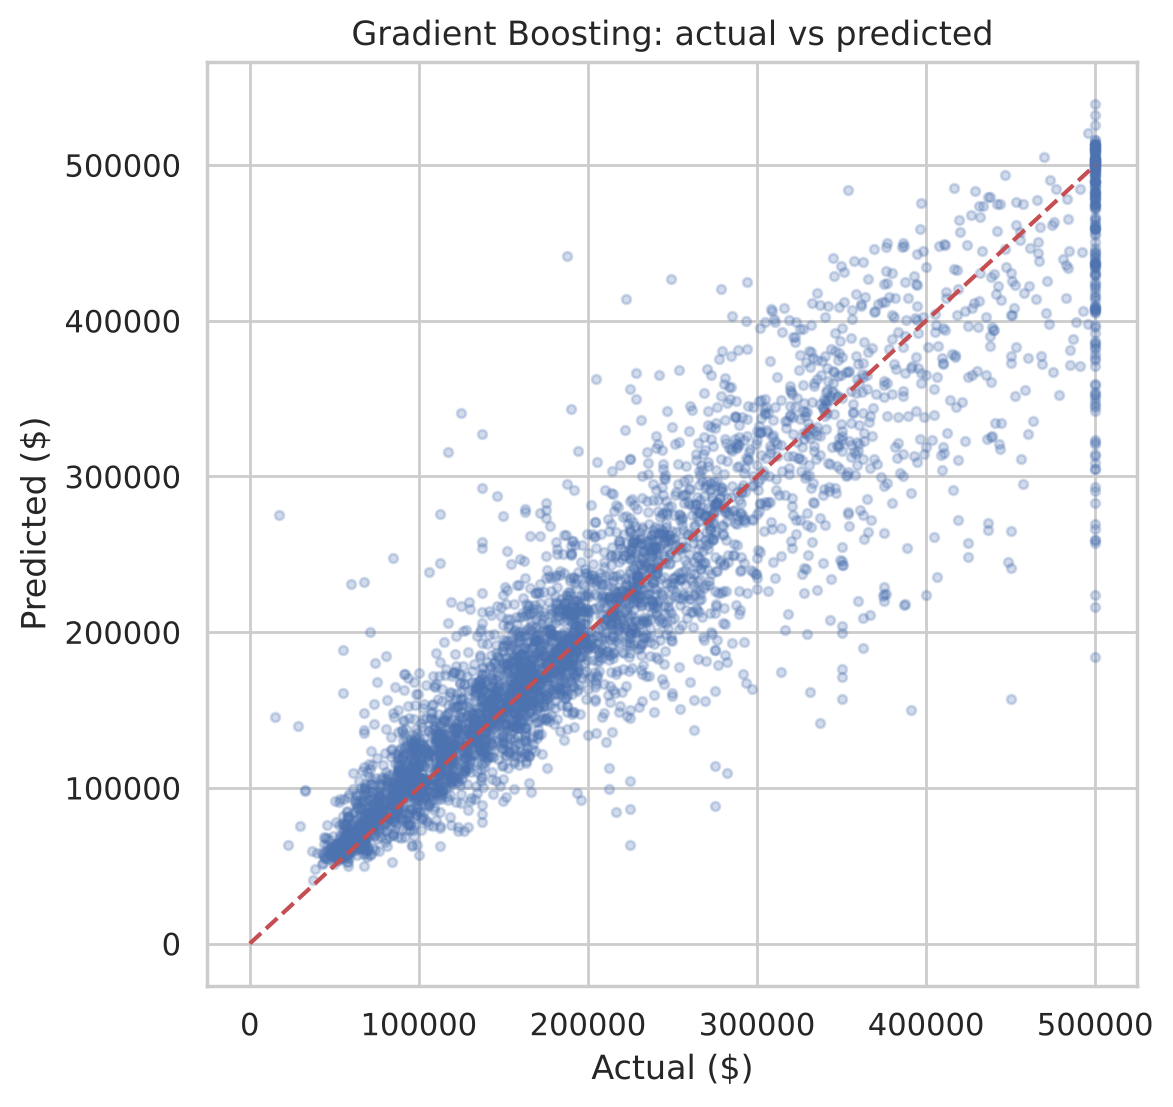

In [11]:
pred = best.predict(X_test)
plt.figure(figsize=(6, 6)); plt.scatter(y_test, pred, alpha=0.25, s=10)
plt.plot([0, 500001], [0, 500001], "r--"); plt.xlabel("Actual ($)"); plt.ylabel("Predicted ($)"); plt.title("Gradient Boosting: actual vs predicted")
plt.savefig("images/actual_vs_predicted.png", dpi=120, bbox_inches="tight"); plt.show()

## 5. Conclusion

* The **from-scratch gradient-descent model matches scikit-learn** (R² ≈ 0.63) — a good check that the maths is right.
* Engineered ratio features help the linear model a little; switching to **tree ensembles**, which can learn the non-linear effect of location, gives the big jump.
* **Gradient Boosting is the final model**: R² goes from **0.626 to 0.849** and the average error drops from **~$50.6k to ~$29.2k** (about 40% lower) compared with the linear baseline.
* Remaining limitation: the $500,001 cap means expensive districts are always under-predicted.